# Madhava-Leibniz π calculation


This notebook is designed to be a live demonstration of Python fundamentals applied to calculating π using the [Madhava-Leibniz series](https://en.wikipedia.org/wiki/Approximations_of_%CF%80#Middle_Ages)

The approximation is simple:

$$ \pi \approx 4 \cdot \left(1 - \frac{1}{3} + \frac{1}{5} - \frac{1}{7} + \frac{1}{9} \ldots -(-1)^n \frac{1}{2n - 1}  \right) $$

Key conceptual and coding vocabulary to watch for:

* *comments*: anything starting with, and to the right of, `#`
* *flow control*: `for` loops
* *flow control*: `if` and `else` statements
* `=` - the variable definition operator; read `pi = 0` as 'computer, store the 0 in the variable named pi'
* `==` - the evaluation operator (checks if two things are equivalent)
* `[]` - an empty list
* `.append()` - add a variable/quantity/etc. to the end of a list
* `range(a,b)` - creates a list of integers between [a,b) (not including b)
* `+`, `-`, `*`, `/` - the addition, subtraction, multiplication, and division operators
* `x**y` - the power operator; read as 'x to the y'
* `print(x)` - prints the contents of x
* indentation - why are some lines indented in python and not other?  What happens if you change this?

In [8]:
#Problem
#How fast does the Madhava-Leibniz series actually converge to pi, and how many terms are needed before the approximation is close enough.
#Method
#Sums the series term by term, keep track of estimate and how far off it is from pi and plot it to see convergence. Then figure out how many steps are needed to obtain accuracy. 
import math
import matplotlib.pyplot as plt
pi_true = math.pi  # what is the actual value of pi

# The Madhava-Leibniz series looks like
# pi = 4 * (1 - 1/3 + 1/5 - 1/7 + 1/9 - ...)
# Each new term flips sign and uses the next odd number on the bottom.

num_terms_to_try = 2000
estimates = []   # keep the running estimate after each term
errors = []      # and how far off that estimate is

running_total = 0
sign = 1  # starts positive, flips every loop

for i in range(num_terms_to_try):
    denom = 2 * i + 1        # 1, 3, 5, 7, ...
    running_total += sign * (4 / denom)
    sign *= -1                # next term gets the opposite sign

    estimates.append(running_total)
    errors.append(abs(running_total - pi_true))

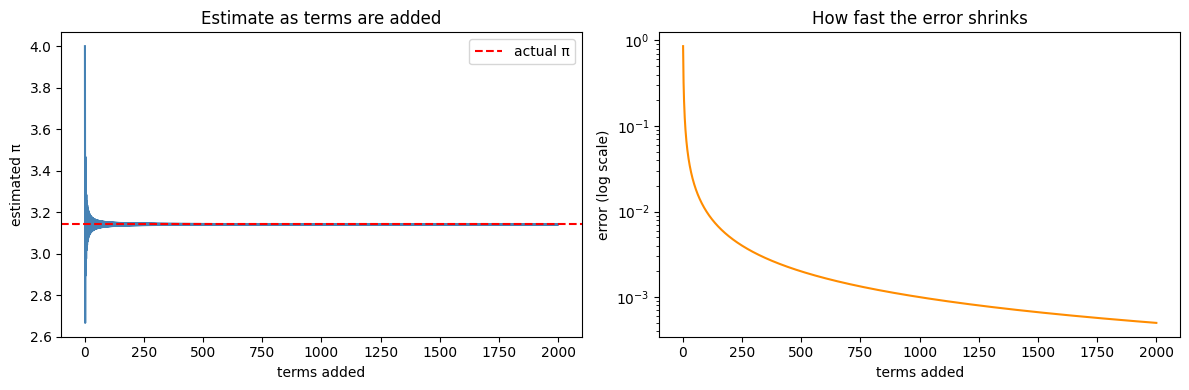

In [9]:
# Plot convergence
term_counts = range(1, num_terms_to_try + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(term_counts, estimates, color='steelblue')
ax1.axhline(pi_true, color='red', linestyle='--', label='actual π')
ax1.set_xlabel('terms added')
ax1.set_ylabel('estimated π')
ax1.set_title('Estimate as terms are added')
ax1.legend()

# error on a log scale, otherwise it just looks like a flat line
ax2.plot(term_counts, errors, color='darkorange')
ax2.set_yscale('log')
ax2.set_xlabel('terms added')
ax2.set_ylabel('error (log scale)')
ax2.set_title('How fast the error shrinks')

plt.tight_layout()
plt.show()

In [13]:
# How many terms until we're close enough? Error < 0.001 is close enough. This is close enough to me as within any calculation I do not think that I would ever notice a .1% difference in a value, whereas I would notice a .5% or 1% difference. 
close_enough = 1e-3

for i, err in enumerate(errors):
    if err < close_enough:
        print(f"Got below {good_enough} after {i + 1} terms (error was {err:.6f})")
        break

Got below 0.001 after 1000 terms (error was 0.001000)


In [14]:
#Function Version
def calculate_pi_madhava(n):
    """
    Approximates pi using the first n terms of the Madhava-Leibniz series.
    More terms = closer to the real value of pi (but it converges slowly).
    """
    total = 0
    sign = 1
    for i in range(n):
        denom = 2 * i + 1
        total += sign * (4 / denom)
        sign *= -1
    return total

In [15]:
# sanity check with a few different term counts
for n in [10, 100, 1000]:
    guess = calculate_pi_madhava(n)
    off_by = abs(guess - pi_true)
    print(f"n={n:>4} -> estimate = {guess:.6f}, off by {off_by:.6f}")
#functions are useful when developing code because they allow you to have one reproducible easily tested package for a repeated calculation.

n=  10 -> estimate = 3.041840, off by 0.099753
n= 100 -> estimate = 3.131593, off by 0.010000
n=1000 -> estimate = 3.140593, off by 0.001000


In [ ]:
#1.
#I simulated the Madhava-Leibniz series for approximating pi, evaluating how many cases would need to exist within the series for me to feel comfortable using this approximation in place of pi. I guess I am a little confused on this part as I do not believe there was an example for this one so I am confused on what I am supposed to compare it to.
#2.
# Not much if I am being honest but the calculation worked as I expected, where if I increase the amount of iterations by 10 times then I am decreasing the error by 10 times.
#3. 
#The first figure shows me that after about 400-500 iterations there is no visible or significant difference by using more iterations and the second graph shows that the added benefit of each sequential iteration is exponentially worth less meaning the value of having the first estimation is worth more than the 2nd and the 2nd is worth more than the third and so on.
#4.
#I kind of answered this in 4 but around 250-400 terms there is not much use in having more iterations as the added benefit is not worth the computational cost. Where that exact number is where the benefit is outweighed by the cost I do not know, but it certainly is not more than 400 iterations. 
#5. 
# Believe it or not this is actually the first genuine function that I have ever made so that concept is something I have learned in this and I also do not have much experience using for loops in my work so that was an added benefit of this homework. 
#6.
# The for loop was slightly challenging to set up but nothing posed a serious challenge to me in completing this assignment. 